In [195]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, classification_report
)
from sklearn.metrics import ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

In [196]:
df = pd.read_csv("ecommerce_customer_churn_dataset.csv")

In [197]:
df.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


In [198]:
df.shape

(50000, 25)

In [199]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  object 
 2   Country                        50000 non-null  object 
 3   City                           50000 non-null  object 
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  float64
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null 

In [200]:
df.describe()

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,...,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.000000,50000.000000,50000.000000,46601.000000,47000.000000,50000.000000,46000.000000,50000.000000,50000.000000,47000.000000,...,45509.000000,47472.000000,49832.000000,46500.000000,44000.000000,45000.000000,47500.000000,50000.000000,44500.000000,50000.000000
mean,37.802968,2.984009,11.624660,27.660754,8.737811,57.079973,4.298391,13.111576,123.117330,29.792872,...,6.680913,20.937980,5.681831,2.853312,29.364466,19.371607,2.353874,1440.626292,1966.233258,0.289000
std,11.834668,2.059105,7.810657,10.871013,3.778220,16.282723,3.189754,7.017312,175.569714,29.695062,...,6.143027,14.252561,2.676052,2.328948,20.574021,9.419252,1.110012,907.249443,1225.072166,0.453302
min,5.000000,0.100000,0.000000,1.000000,1.000000,0.000000,0.000000,-13.000000,26.380000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,29.000000,1.400000,6.000000,19.700000,6.000000,46.400000,2.000000,8.000000,87.050000,9.000000,...,2.900000,9.900000,4.000000,1.000000,13.200000,12.500000,2.000000,789.817500,1049.000000,0.000000
50%,38.000000,2.500000,11.000000,26.800000,8.400000,58.100000,4.000000,12.000000,112.970000,21.000000,...,5.400000,19.700000,5.000000,2.000000,27.600000,18.600000,2.000000,1243.415000,1896.000000,0.000000
75%,46.000000,4.000000,17.000000,34.700000,11.200000,68.700000,6.000000,17.000000,144.440000,41.000000,...,9.100000,30.400000,7.000000,4.000000,43.100000,25.500000,3.000000,1874.000000,2791.000000,1.000000
max,200.000000,10.000000,46.000000,75.600000,24.100000,143.743350,28.000000,128.700000,9666.379178,287.000000,...,99.615734,91.700000,21.000000,21.000000,100.000000,61.900000,5.000000,8987.240000,7197.000000,1.000000


In [201]:
(df.isnull().sum()/len(df)) * 100

Age                               4.990
Gender                            0.000
Country                           0.000
City                              0.000
Membership_Years                  0.000
Login_Frequency                   0.000
Session_Duration_Avg              6.798
Pages_Per_Session                 6.000
Cart_Abandonment_Rate             0.000
Wishlist_Items                    8.000
Total_Purchases                   0.000
Average_Order_Value               0.000
Days_Since_Last_Purchase          6.000
Discount_Usage_Rate               7.000
Returns_Rate                      8.982
Email_Open_Rate                   5.056
Customer_Service_Calls            0.336
Product_Reviews_Written           7.000
Social_Media_Engagement_Score    12.000
Mobile_App_Usage                 10.000
Payment_Method_Diversity          5.000
Lifetime_Value                    0.000
Credit_Balance                   11.000
Churned                           0.000
Signup_Quarter                    0.000


In [202]:
df.duplicated().sum()

np.int64(0)

In [203]:
num_cols = df.select_dtypes(include=["int64","float64"]).columns.drop("Churned")
cat_cols = df.select_dtypes(include=["object"]).columns

In [204]:
num_cols

Index(['Age', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg',
       'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items',
       'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase',
       'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate',
       'Customer_Service_Calls', 'Product_Reviews_Written',
       'Social_Media_Engagement_Score', 'Mobile_App_Usage',
       'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance'],
      dtype='object')

In [205]:
cat_cols

Index(['Gender', 'Country', 'City', 'Signup_Quarter'], dtype='object')

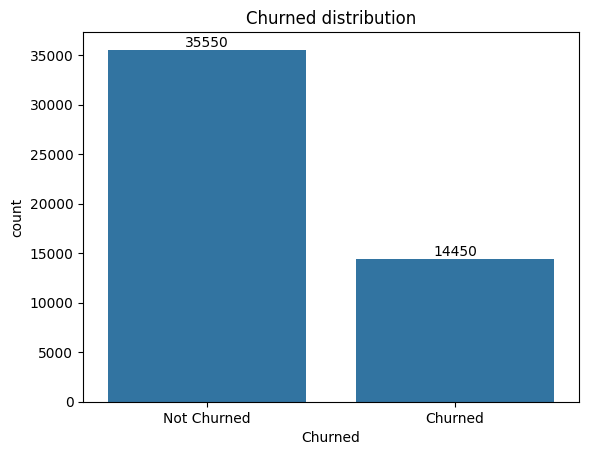

In [206]:
ax = sns.countplot(data=df,x="Churned")
ax.bar_label(ax.containers[0])
plt.title("Churned distribution")
plt.xticks([0,1],["Not Churned","Churned"])
plt.show()

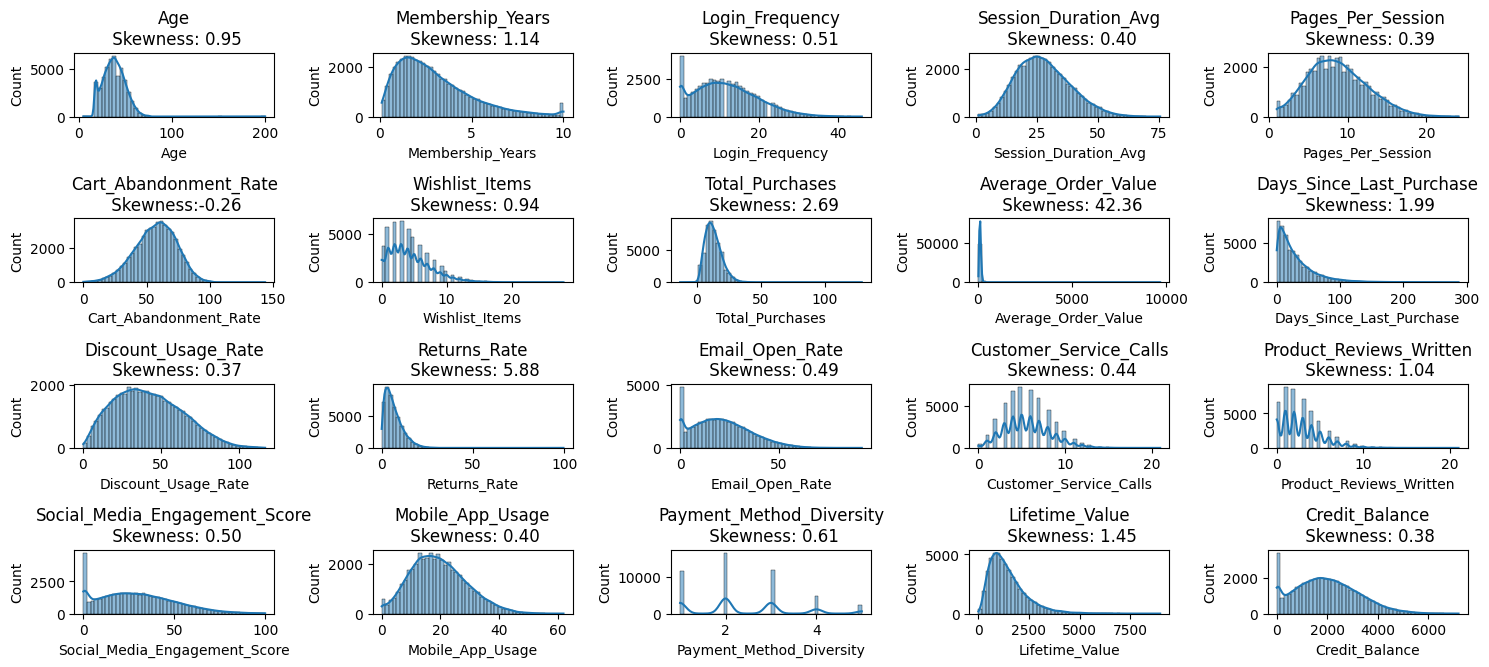

In [207]:
plt.figure(figsize=(15,8))
for i,col in enumerate(num_cols,1):
    plt.subplot(5,5,i)
    sns.histplot(df[col],bins=50,kde=True)
    plt.title(f"{col}\n Skewness:{df[col].skew() : .2f}")
plt.tight_layout()
plt.show()

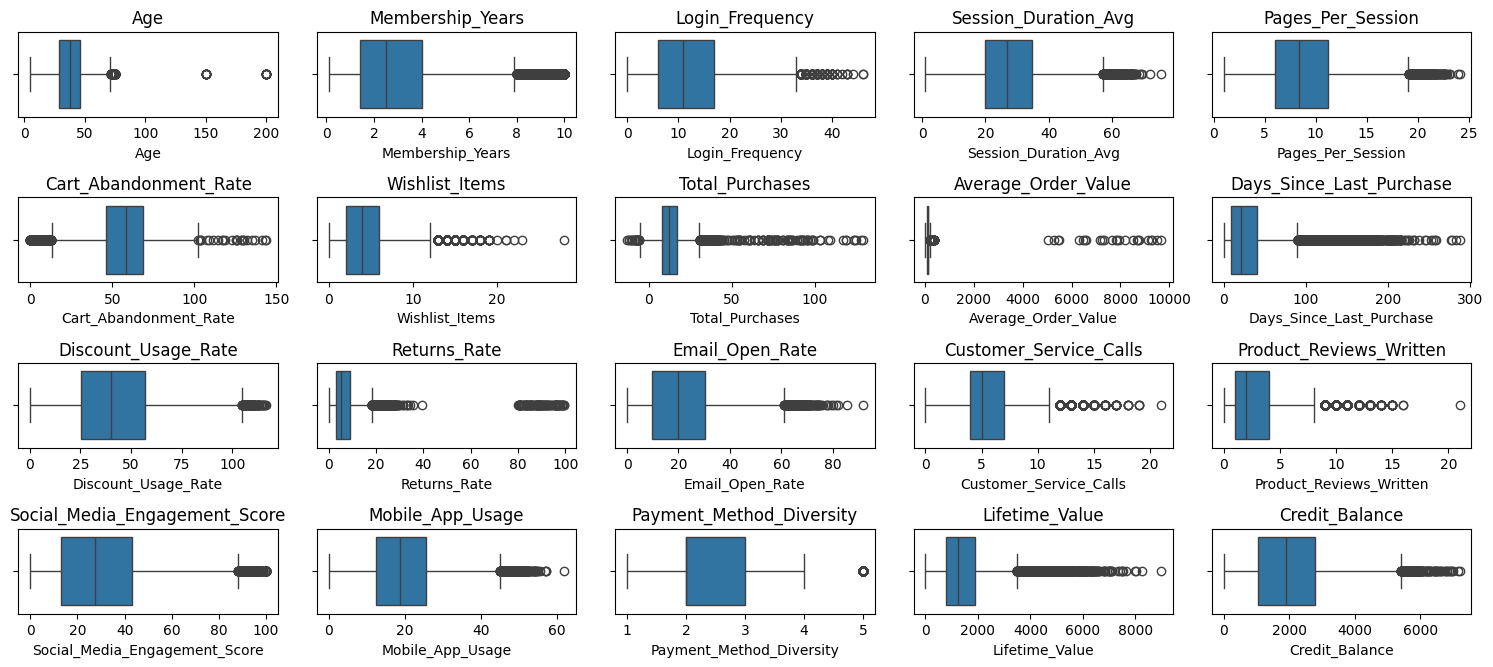

In [208]:
plt.figure(figsize=(15,8))
for i,col in enumerate(num_cols,1):
    plt.subplot(5,5,i)
    sns.boxplot(data=df,x=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [209]:
cat_cols

Index(['Gender', 'Country', 'City', 'Signup_Quarter'], dtype='object')

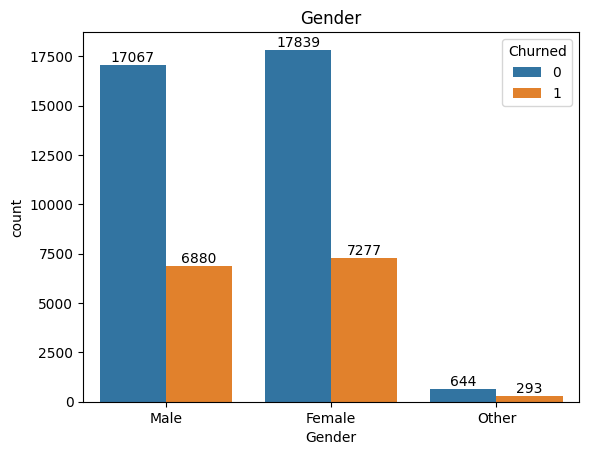

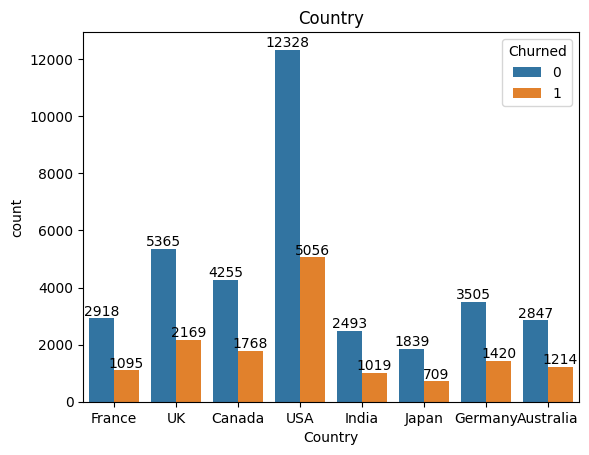

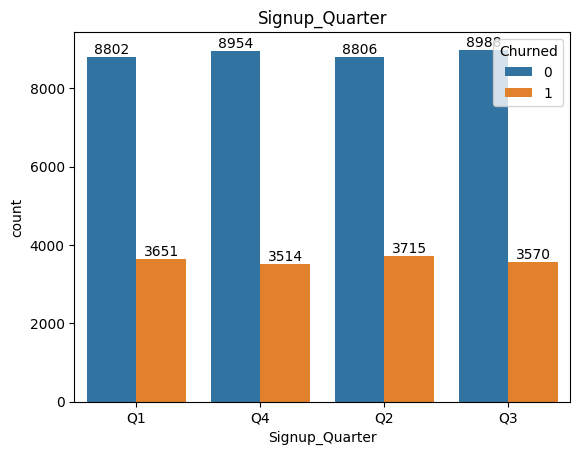

In [210]:
cols = ["Gender","Country","Signup_Quarter"]
for col in cols:
    ax = sns.countplot(data=df,x=col,hue="Churned")
    for container in ax.containers:
        ax.bar_label(container)
    plt.title(col)
    plt.show()

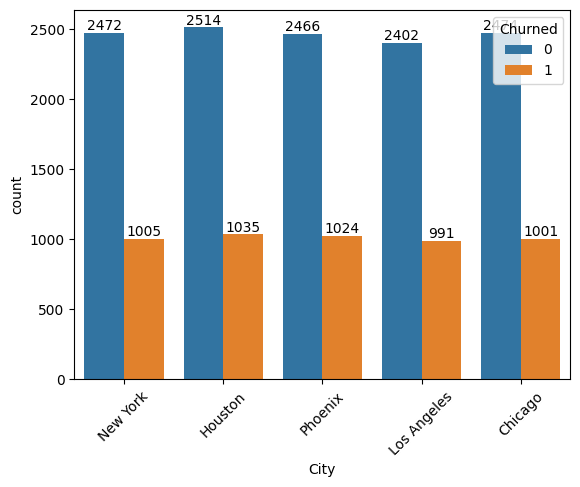

In [211]:
top5_cities = df["City"].value_counts().head(5).index
df_top5_cities = df[df["City"].isin(top5_cities)]
ax = sns.countplot(data=df_top5_cities,x="City",hue="Churned")
for container in ax.containers:
    ax.bar_label(container)
plt.xticks(rotation=45)
plt.show()

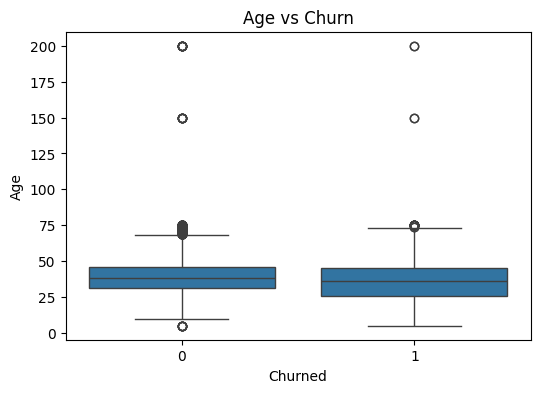

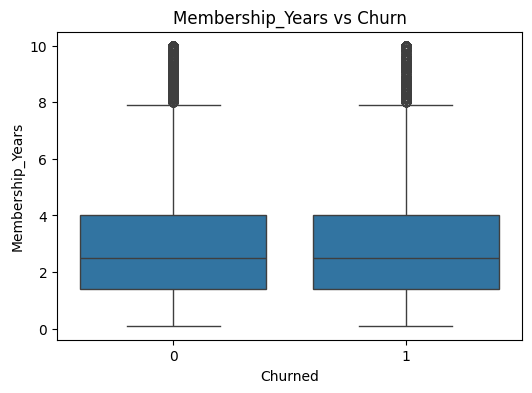

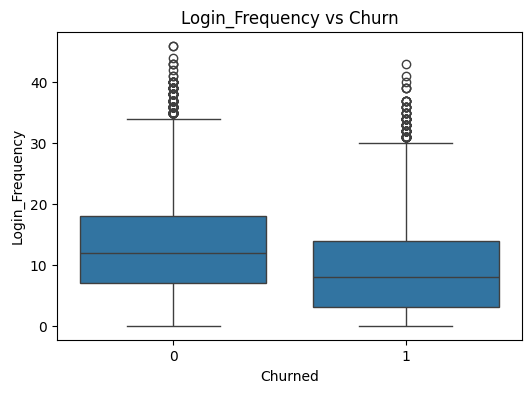

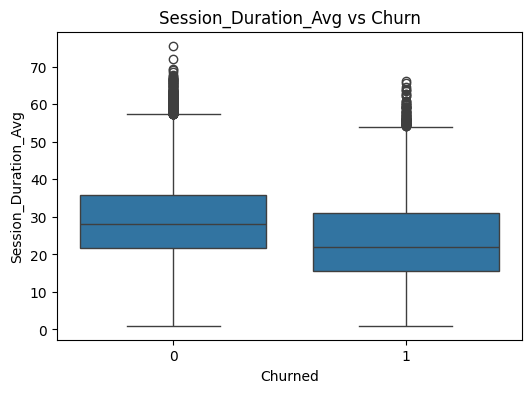

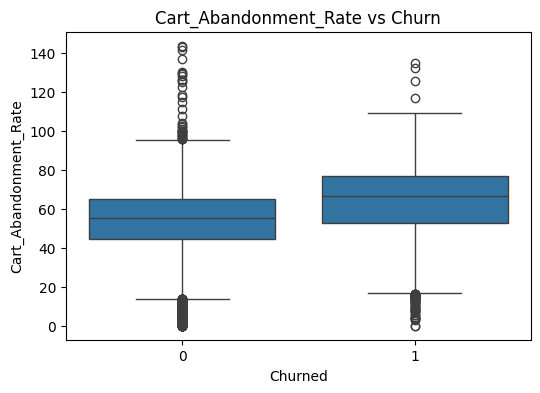

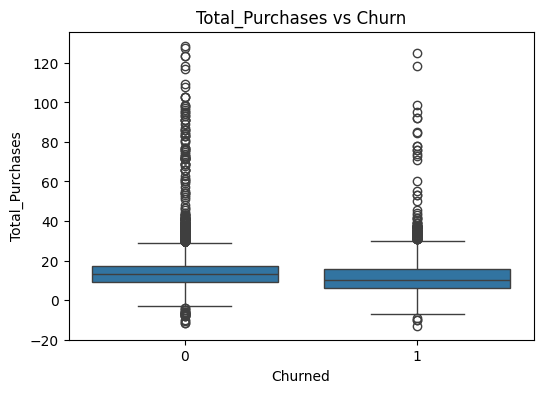

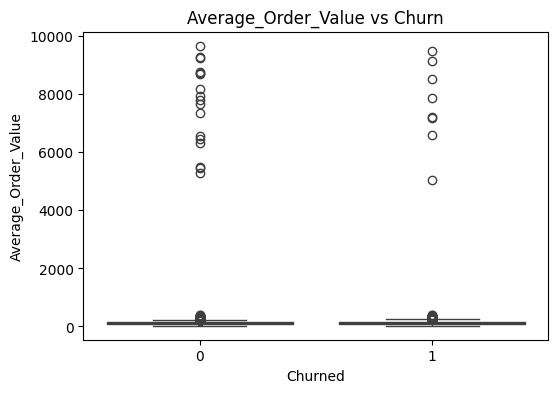

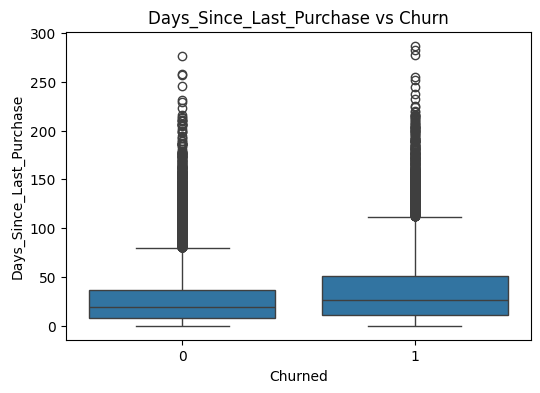

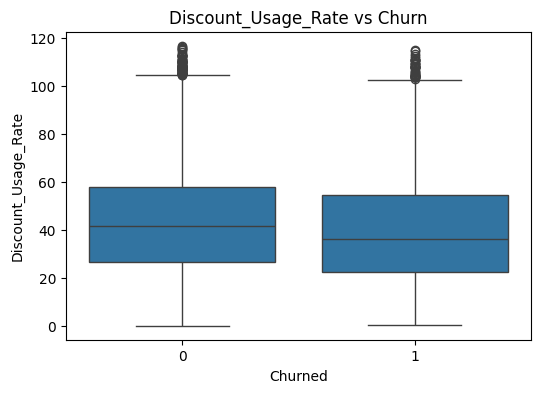

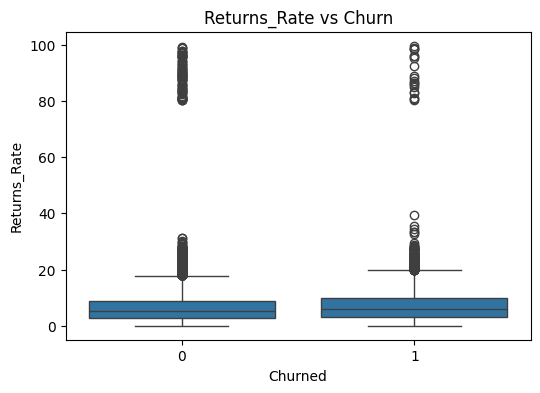

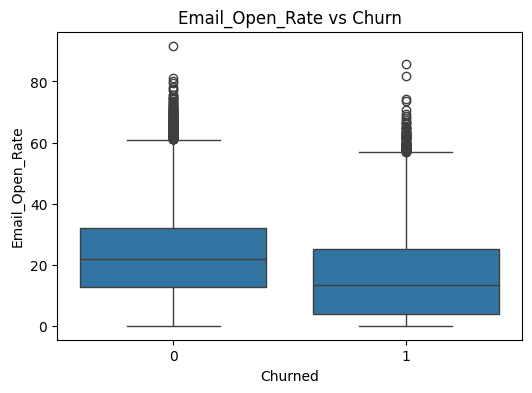

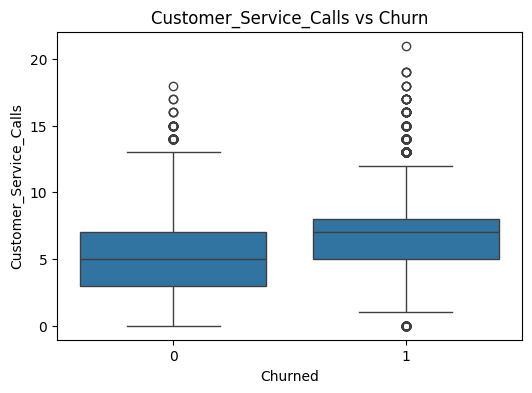

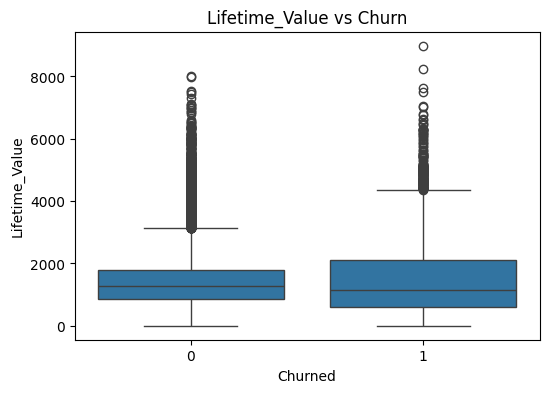

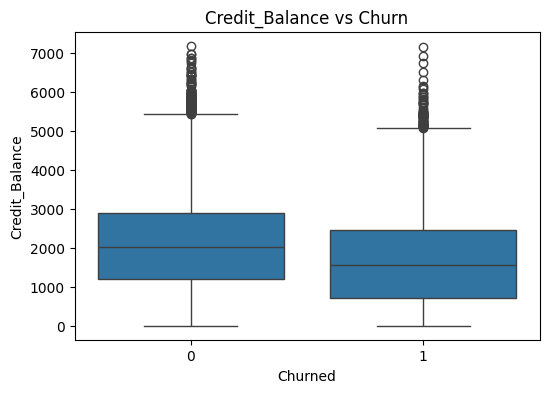

In [212]:
important_cols = [
    "Age",
    "Membership_Years",
    "Login_Frequency",
    "Session_Duration_Avg",
    "Cart_Abandonment_Rate",
    "Total_Purchases",
    "Average_Order_Value",
    "Days_Since_Last_Purchase",
    "Discount_Usage_Rate",
    "Returns_Rate",
    "Email_Open_Rate",
    "Customer_Service_Calls",
    "Lifetime_Value",
    "Credit_Balance"
]

for col in important_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="Churned",y=col,data=df)
    plt.title(f'{col} vs Churn')
    plt.show()

In [213]:
df.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


In [214]:
corr = df.select_dtypes(include="number").corr()
corr["Churned"].sort_values(ascending=False)

Churned                          1.000000
Customer_Service_Calls           0.291103
Cart_Abandonment_Rate            0.277963
Days_Since_Last_Purchase         0.153360
Returns_Rate                     0.054189
Average_Order_Value              0.042288
Payment_Method_Diversity         0.004524
Membership_Years                -0.000623
Lifetime_Value                  -0.010684
Discount_Usage_Rate             -0.077121
Age                             -0.102849
Credit_Balance                  -0.156921
Total_Purchases                 -0.160029
Product_Reviews_Written         -0.181225
Social_Media_Engagement_Score   -0.191792
Wishlist_Items                  -0.197708
Login_Frequency                 -0.204379
Email_Open_Rate                 -0.222213
Mobile_App_Usage                -0.222876
Session_Duration_Avg            -0.228010
Pages_Per_Session               -0.231799
Name: Churned, dtype: float64

In [215]:
df.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


In [216]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df[col] = np.where(df[col] < lower,lower,
                       np.where(df[col] > upper,upper,df[col]))

In [217]:
X = df.drop("Churned",axis=1)
y = df["Churned"]

In [218]:
df.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,8.5,83.0,45.0,4.0,3041.29,5354.0,0,Q4


In [219]:
num_cols = X.select_dtypes(include=["int64","float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

In [220]:
X.dtypes

Age                              float64
Gender                            object
Country                           object
City                              object
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance                   float64
Signup_Quarter                    object
dtype: object

In [221]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [222]:
# Numerical pipeline
num_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

In [223]:
# categorical pipeline
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe",OneHotEncoder(handle_unknown="ignore",drop="first"))
])

In [224]:
preprocessor = ColumnTransformer([
    ("num",num_pipeline,num_cols),
    ("cat_ohe",cat_pipeline,cat_cols)
])

In [225]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        n_jobs=-1,
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    ),  
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        n_jobs=-1,
        random_state=42
    )
}

In [226]:
results = []
for name,model in models.items():
    pipe = Pipeline([
        ("preprocessing",preprocessor),
        ("model",model)
    ])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:,-1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values(by=["Recall","F1","ROC_AUC"],ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,0.9184,0.910206,0.796194,0.849391,0.928146
1,Gradient Boosting,0.9198,0.937552,0.774048,0.847991,0.927929
2,Random Forest,0.9135,0.920648,0.766782,0.836700,0.924124
3,Decision Tree,0.8396,0.716207,0.737024,0.726467,0.809159
4,SVM,0.8764,0.858630,0.685121,0.762125,0.902791
5,Logistic Regression,0.7757,0.673273,0.434948,0.528484,0.793902


### **Selected Model : XGBoost**

In [227]:
pipe = Pipeline([
    ("preprocesing", preprocessor),
    ("model_xgb", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

params_dist = {
    "model_xgb__n_estimators": [100, 200, 300, 500],
    "model_xgb__max_depth": [3, 4, 5, 6, 8, 10],
    "model_xgb__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model_xgb__subsample": [0.7, 0.8, 0.9, 1.0],
    "model_xgb__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model_xgb__min_child_weight": [1, 3, 5, 7],
    "model_xgb__gamma": [0, 0.1, 0.2, 0.5],
    "model_xgb__reg_alpha": [0, 0.01, 0.1, 1],
    "model_xgb__reg_lambda": [1, 1.5, 2, 5]
}

xgb_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=params_dist,
    n_iter=50,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model_xgb__colsample_bytree': [0.7, 0.8, ...], 'model_xgb__gamma': [0, 0.1, ...], 'model_xgb__learning_rate': [0.01, 0.03, ...], 'model_xgb__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-valida

In [228]:
print("Best Parameters:")
print(xgb_search.best_params_)

print("Best CV F1:") 
print(xgb_search.best_score_)

Best Parameters:
{'model_xgb__subsample': 1.0, 'model_xgb__reg_lambda': 2, 'model_xgb__reg_alpha': 0.1, 'model_xgb__n_estimators': 500, 'model_xgb__min_child_weight': 3, 'model_xgb__max_depth': 6, 'model_xgb__learning_rate': 0.03, 'model_xgb__gamma': 0.2, 'model_xgb__colsample_bytree': 0.8}
Best CV F1:
0.8526500825229583


In [230]:
best_xgb = xgb_search.best_estimator_
y_pred = best_xgb.predict(X_test)
y_prob = best_xgb.predict_proba(X_test)[:,1]

In [231]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.9236
Precision: 0.9265650080256822
Recall   : 0.798961937716263
F1 Score : 0.8580453363062058
ROC AUC  : 0.9295459390010657

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.95      7110
           1       0.93      0.80      0.86      2890

    accuracy                           0.92     10000
   macro avg       0.92      0.89      0.90     10000
weighted avg       0.92      0.92      0.92     10000



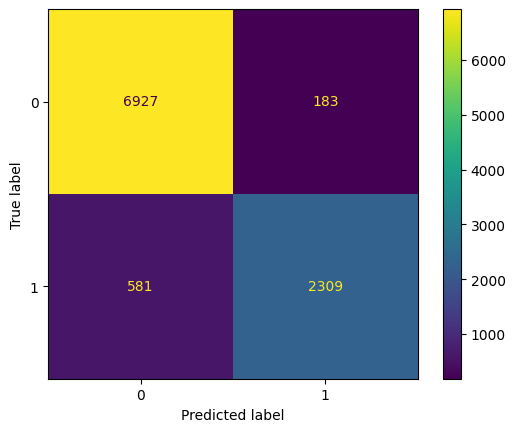

In [232]:
ConfusionMatrixDisplay.from_estimator(best_xgb,X_test,y_test)

### Feature Importance

In [234]:
# Get feature names after preprocessing
feature_names = best_xgb.named_steps["preprocesing"].get_feature_names_out()

# Get trained XGBoost model
xgb_model = best_xgb.named_steps["model_xgb"]

# Get feature importance
importance = xgb_model.feature_importances_

# Create DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(10)

,Feature,Importance
13,num__Customer_Service_Calls,0.149697
18,num__Lifetime_Value,0.128150
10,num__Discount_Usage_Rate,0.090222
5,num__Cart_Abandonment_Rate,0.067868
7,num__Total_Purchases,0.053791
0,num__Age,0.048959
9,num__Days_Since_Last_Purchase,0.029960
12,num__Email_Open_Rate,0.026630
6,num__Wishlist_Items,0.023812
14,num__Product_Reviews_Written,0.019707


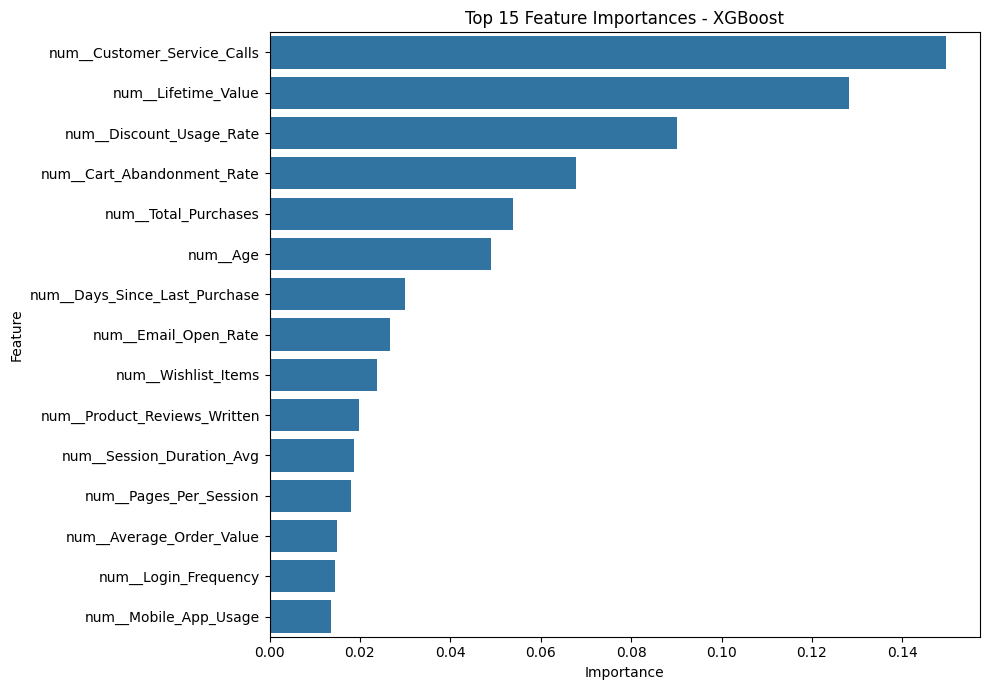

In [235]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Key Finding

- **Customer Service Calls was the most important feature (14.97%) for predicting customer churn.**
  
- **Lifetime Value was the second most important feature (12.81%).**

- **Discount Usage Rate (9.02%) and Cart Abandonment Rate (6.78%) were also important predictors.**

- **Total Purchases (5.38%) and Age (4.90%) also contributed to churn prediction.**

- **Customer service interactions, purchasing behavior, and customer engagement were important factors in the model's predictions.**

# Conclusion

**XGBoost was selected as the final model after hyperparameter tuning. The tuned model achieved 92% accuracy.**

**For the customer churn class (Class 1), the model achieved 93% precision, 80% recall, and an F1-score of 86%.**

**The model provides a good balance between precision and recall, although it still misses some customers who are likely to churn. Therefore, the tuned XGBoost model was selected as the final model for customer churn prediction.**

<div style="border:3px solid #1f77b4;padding:20px;text-align:center;border-radius:10px;">
  <span style="font-size:36px;font-weight:bold;color:#1f77b4;">
     Final Model: XGBoost
  </span>
</div>

In [236]:
import joblib
joblib.dump(best_xgb,"customer_churn_model.pkl")

['customer_churn_model.pkl']